In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [4]:
df = pd.read_csv("D:\\sem-7 LP3\\uber.csv")
df = df.drop(["Unnamed: 0", "key"], axis=1) 
df = df.dropna()                                
df = df.drop_duplicates()            

In [5]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df = df.drop("pickup_datetime", axis=1)

In [6]:
df = df[df["fare_amount"] > 0]
df = df[(df["passenger_count"] > 0) & (df["passenger_count"] <= 6)]
df = df[(df["pickup_latitude"].between(-90, 90)) & (df["dropoff_latitude"].between(-90, 90))]
df = df[(df["pickup_longitude"].between(-180, 180)) & (df["dropoff_longitude"].between(-180, 180))]

In [7]:
lat1 = np.radians(df["pickup_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon2 = np.radians(df["dropoff_longitude"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

In [8]:
df = df[df["distance"] > 0]
print("Data shape after cleaning:", df.shape)

Data shape after cleaning: (193644, 11)


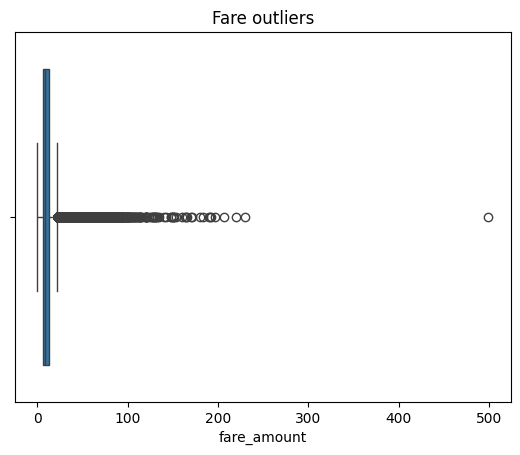

In [9]:
sns.boxplot(x=df["fare_amount"])
plt.title("Fare outliers")
plt.show()

In [10]:
def remove_outliers(data, col):
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    print(col, "outliers:", len(data[(data[col] < low) | (data[col] > high)]))
    return data[(data[col] >= low) & (data[col] <= high)]

df = remove_outliers(df, "fare_amount")
df = remove_outliers(df, "distance")

fare_amount outliers: 16619
distance outliers: 8006


fare_amount          1.000000
distance             0.795531
year                 0.173208
month                0.032687
passenger_count      0.016702
hour                 0.006767
day                  0.004776
dropoff_longitude    0.002899
pickup_longitude     0.002472
pickup_latitude     -0.003313
dropoff_latitude    -0.003678
Name: fare_amount, dtype: float64


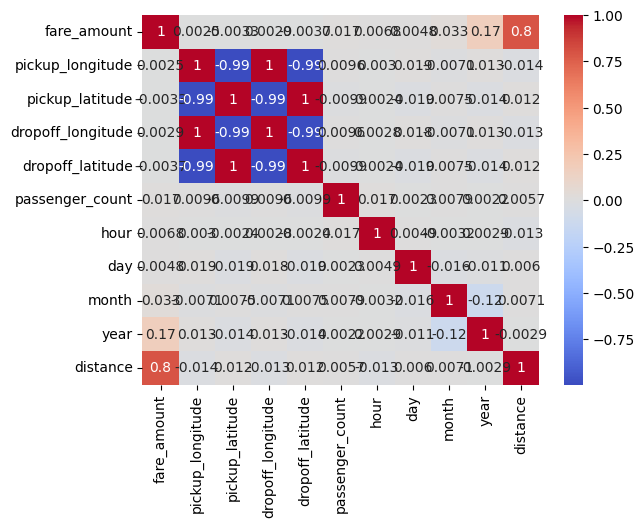

In [11]:
corr = df.corr()
print(corr["fare_amount"].sort_values(ascending=False))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

In [12]:
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [13]:
def evaluate(name, actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(name, "-> R2:", round(r2, 4), ", RMSE:", round(rmse, 4))

print("\nModel Comparison")
evaluate("Linear Regression", y_test, lr_pred)
evaluate("Random Forest    ", y_test, rf_pred)


Model Comparison
Linear Regression -> R2: 0.6729 , RMSE: 2.1272
Random Forest     -> R2: 0.7435 , RMSE: 1.8836
